In [65]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

filename = r"exoplanets_slim_2026-11-3.csv"

df = pd.read_csv(
    filename,
    header=0
)

# making columns titles more readable
df = df.rename(columns={
    "pl_name": "pl_name",
    "hostname": "host_name",

    "sy_snum": "sys_num_star",
    "sy_pnum": "sys_num_planet",
    "sy_dist": "sys_dist_e",

    "discoverymethod": "disc_method",
    #"disc_year": "",
    #"disc_facility": "",

    #"pl_controv_flag": "",
    "pl_eqt": "pl_temp",
    "pl_insol": "pl_insol_flux",

    "pl_orbper": "pl_orb_period",
    "pl_orbeccen": "pl_orb_eccen",
    "pl_orbsmax": "pl_orb_semimajor_axis",

    "pl_rade": "pl_radius_e",
    "pl_bmasse": "pl_mass_e",
    "pl_bmassprov": "pl_mass_prov",

    "st_teff": "st_temp",
    "st_rad": "st_radius",
    #"st_mass": "",
    "st_met": "st_metal",
    "st_logg": "st_gravity",
    #"st_age": "",
    })

print(df.shape)
print(df.dtypes)

(6451, 23)
pl_name                      str
host_name                    str
sys_num_star               int64
sys_num_planet             int64
sys_dist_e               float64
disc_method                  str
disc_year                  int64
disc_facility                str
pl_controv_flag            int64
pl_temp                  float64
pl_insol_flux            float64
pl_orb_period            float64
pl_orb_eccen             float64
pl_orb_semimajor_axis    float64
pl_radius_e              float64
pl_mass_e                float64
pl_mass_prov                 str
st_temp                  float64
st_radius                float64
st_mass                  float64
st_metal                 float64
st_gravity               float64
st_age                   float64
dtype: object


In [71]:
import numpy as np
import pandas as pd

featuresPhysical = ["pl_radius_e", "st_mass", "st_temp", "st_radius", "sys_num_planet"]
featuresDiscovery = ["disc_year", "sys_dist_e", "disc_method"]

d = df.dropna(subset=featuresPhysical + featuresDiscovery + ["pl_orb_period"]).copy()
d = d[d["pl_orb_period"] > 0]
d["log_period"] = np.log10(d["pl_orb_period"])
y = d["log_period"]

print(len(df), "->", len(d))

6451 -> 5994


In [72]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

trainIdx, testIdx = train_test_split(d.index, test_size=0.2, random_state=42)
yTrain, yTest = y.loc[trainIdx], y.loc[testIdx]

# baseline prediction for comparison
baseline = np.full(len(yTest), yTrain.mean())
baselineRmse = np.sqrt(mean_squared_error(yTest, baseline))
print("baseline RMSE:", baselineRmse)

baseline RMSE: 0.918644906236069


In [73]:
featureSets = {
    "discovery only": featuresDiscovery,
    "astrophysical only": featuresPhysical,
    "both": featuresPhysical + featuresDiscovery,
}

rows = []
preds = {}

for name, cols in featureSets.items():
    x = pd.get_dummies(d[cols])
    xTrain, xTest = x.loc[trainIdx], x.loc[testIdx]

    tree = DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=42)
    tree.fit(xTrain, yTrain)
    pred = tree.predict(xTest)
    preds[name] = pred

    cv = cross_val_score(tree, xTrain, yTrain, cv=5, scoring="r2")
    rows.append({
        "features": name,
        "test_R2": r2_score(yTest, pred),
        "test_RMSE": np.sqrt(mean_squared_error(yTest, pred)),
        "CV_R2": cv.mean(),
    })

results = pd.DataFrame(rows)
results["typical_miss_factor"] = 10 ** results["test_RMSE"]
print(results.round(3))

             features  test_R2  test_RMSE  CV_R2  typical_miss_factor
0      discovery only    0.472      0.668  0.400                4.652
1  astrophysical only    0.432      0.692  0.426                4.924
2                both    0.661      0.535  0.623                3.425


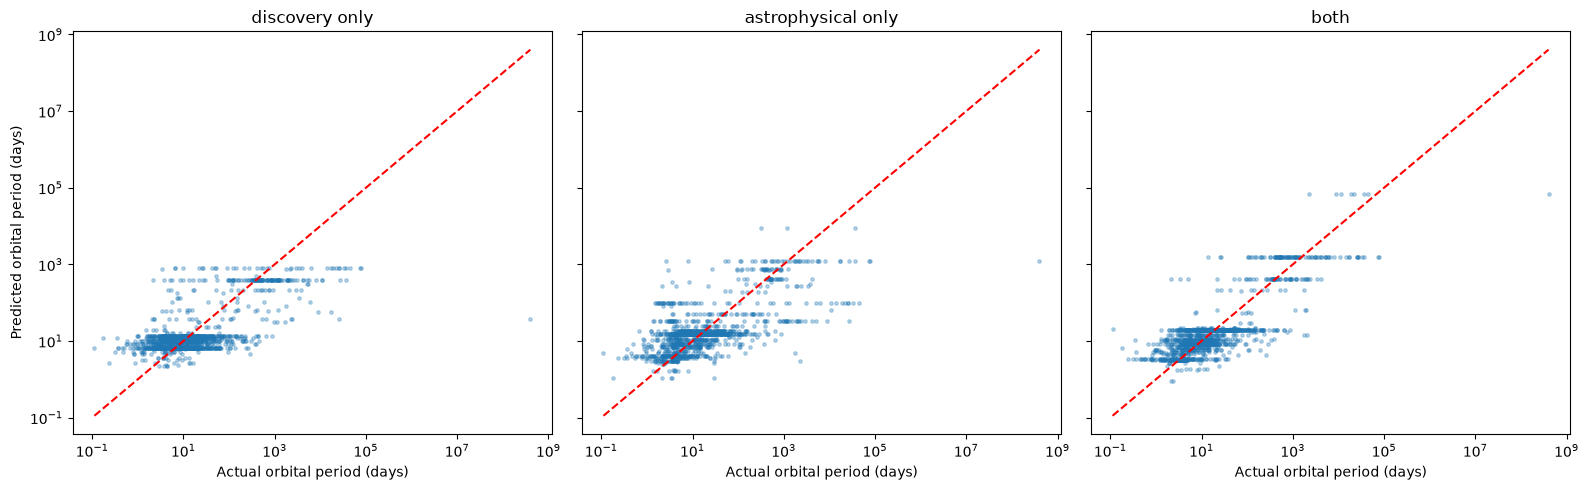

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)

for ax, name in zip(axes, featureSets):
    ax.scatter(10 ** yTest, 10 ** preds[name], s=6, alpha=0.3)
    lims = [10 ** yTest.min(), 10 ** yTest.max()]
    ax.plot(lims, lims, "r--")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(name)
    ax.set_xlabel("Actual orbital period (days)")

axes[0].set_ylabel("Predicted orbital period (days)")
plt.tight_layout()
plt.show()

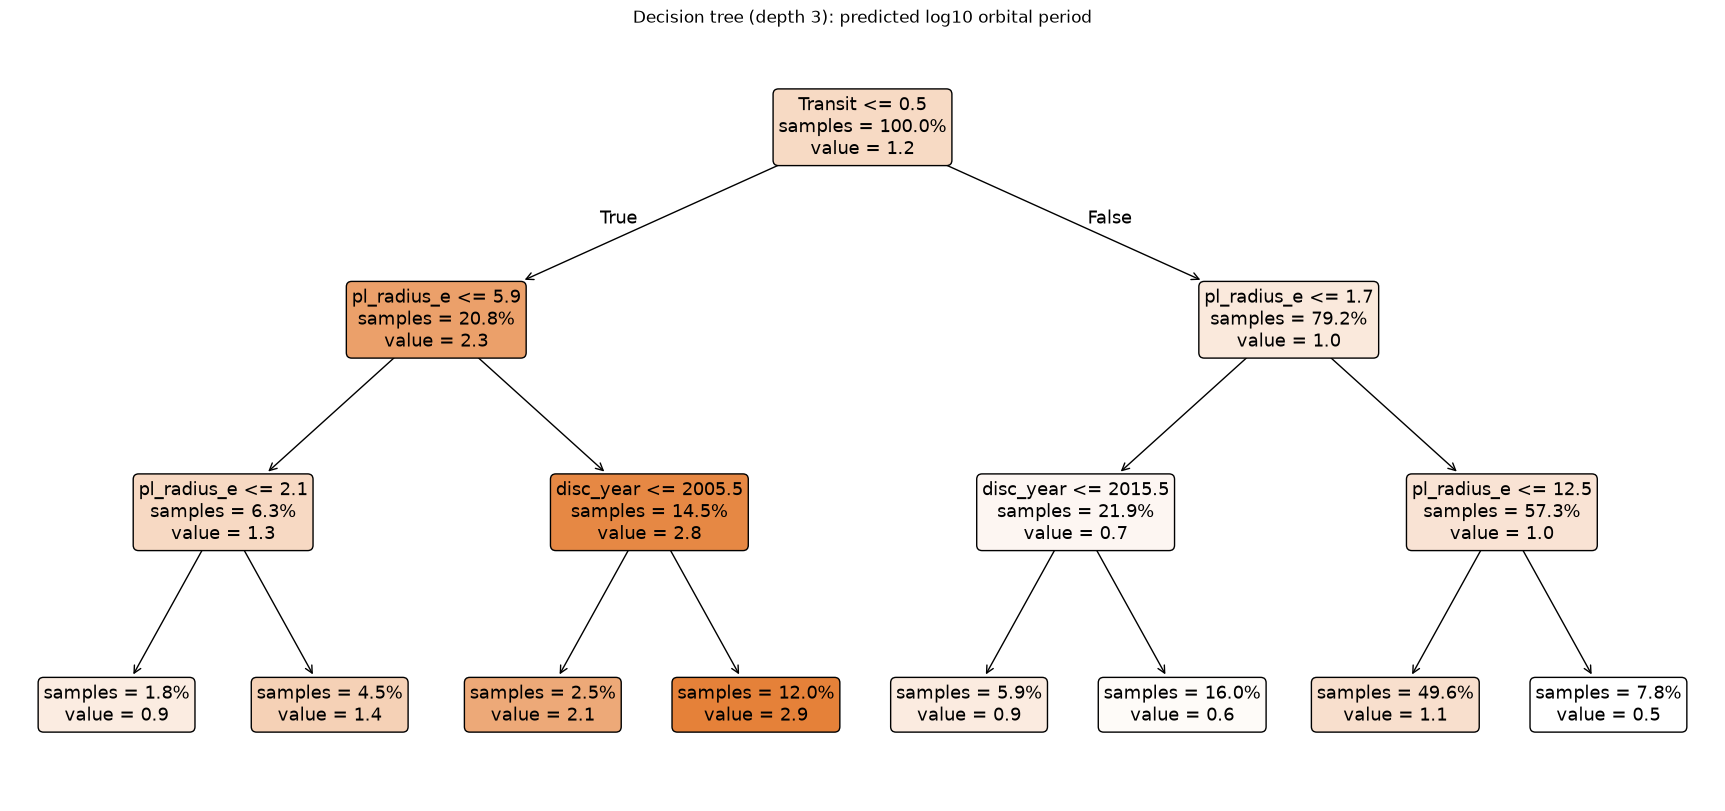

In [75]:
from sklearn.tree import plot_tree

x = pd.get_dummies(d[featuresPhysical + featuresDiscovery])
x.columns = [c.replace("disc_method_", "") for c in x.columns]   # shorter labels

small = DecisionTreeRegressor(max_depth=3, min_samples_leaf=30, random_state=42)
small.fit(x.loc[trainIdx], yTrain)

plt.figure(figsize=(22, 10))
plot_tree(
    small,
    feature_names=list(x.columns),
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    fontsize=13,
    precision=1,
)
plt.title("Decision tree (depth 3): predicted log10 orbital period")
plt.show()